# 04 — Analisis Domain Shift, 5 Kasus Kegagalan, & Eksperimen Uji Hipotesis
**Runtime:** GPU T4 (atau CPU jika hanya membuat grafik rekap).

Notebook ini membantu menghasilkan seluruh grafik dan bukti eksperimen kecil untuk laporan:
1. **Tabel & Grafik Domain Shift**: Perbandingan performa 3 model di `Test_Asli` vs `Test_HP_Sendiri` serta selisih (Δ mAP).
2. **Grafik Eksperimen NRP 0**: Pengaruh ukuran input `320` vs `640` vs `960`.
3. **Visualisasi 5 Foto Gagal** dari Test Set HP Anda.
4. **Eksperimen Kecil Uji Hipotesis Kegagalan**:
   - Uji A (Mekanisme resolusi prototype mask YOLO): Bandingkan prediksi foto yang sama di `imgsz=320` vs `640` vs `960`.
   - Uji B (Kondisi *low-light / backlight*): Terapkan **CLAHE** (peningkatan kontras adaptif) pada foto gagal lalu inferensi ulang untuk membuktikan apakah kegagalan disebabkan oleh kontras pencahayaan.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics opencv-python-headless matplotlib pandas

import os, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = '/content/drive/MyDrive/cpmk3-instance-segmentation'
LOGS_DIR    = os.path.join(PROJECT_DIR, 'logs')
EXPORTS_DIR = os.path.join(PROJECT_DIR, 'exports')
os.makedirs(EXPORTS_DIR, exist_ok=True)

dfs = []
for fname in ['eval_yolov8_seg.csv', 'eval_maskrcnn.csv', 'eval_mask2former.csv']:
    p = os.path.join(LOGS_DIR, fname)
    if os.path.exists(p):
        dfs.append(pd.read_csv(p))

df_all = pd.concat(dfs, ignore_index=True)
df_all.to_csv(os.path.join(EXPORTS_DIR, 'summary_all_models.csv'), index=False)
df_all


Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


,model,architecture_family,imgsz,dataset,box_mAP50,box_mAP50_95,mask_mAP50,mask_mAP50_95,eval_time_sec
0,YOLOv8s-seg,One-Stage CNN,320,Test_Asli,0.1539,0.1063,0.1403,0.0868,166.52
1,YOLOv8s-seg,One-Stage CNN,320,Test_HP_Sendiri,0.0792,0.0540,0.0735,0.0341,52.97
2,YOLOv8s-seg,One-Stage CNN,640,Test_Asli,0.2120,0.1512,0.2004,0.1306,18.88
3,YOLOv8s-seg,One-Stage CNN,640,Test_HP_Sendiri,0.2054,0.1422,0.1937,0.1150,11.53
4,YOLOv8s-seg,One-Stage CNN,960,Test_Asli,0.1955,0.1397,0.1856,0.1236,21.87
5,YOLOv8s-seg,One-Stage CNN,960,Test_HP_Sendiri,0.1875,0.1555,0.1780,0.1179,10.77


## 1. Analisis Domain Shift (Selisih Test Asli vs Test HP Sendiri)


dataset                          Test_Asli  Test_HP_Sendiri  \
model       architecture_family                               
YOLOv8s-seg One-Stage CNN           0.2004           0.1937   

dataset                          Delta_Domain_Shift  
model       architecture_family                      
YOLOv8s-seg One-Stage CNN                   -0.0067  


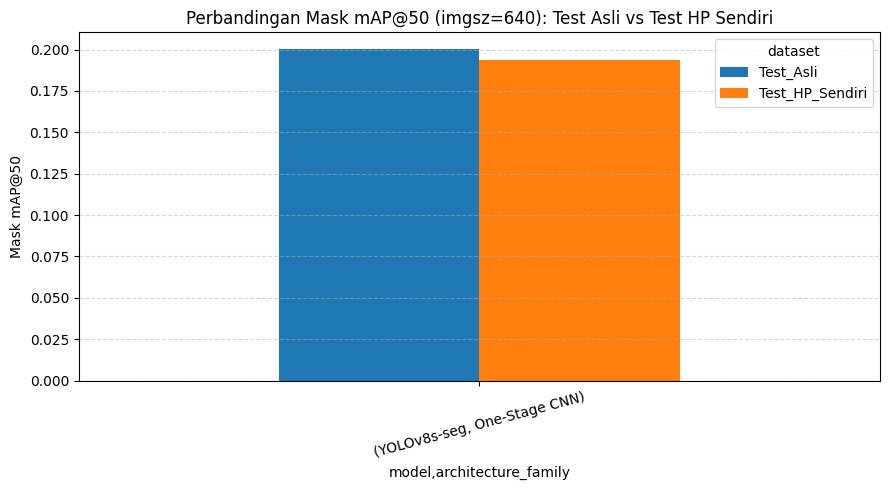

In [ ]:
# Fokus perbandingan antar 3 model di ukuran baseline 640
df_640 = df_all[df_all['imgsz'] == 640]
pivot = df_640.pivot(index=['model', 'architecture_family'], columns='dataset', values='mask_mAP50')
if 'Test_Asli' in pivot.columns and 'Test_HP_Sendiri' in pivot.columns:
    pivot['Delta_Domain_Shift'] = (pivot['Test_HP_Sendiri'] - pivot['Test_Asli']).round(4)
print(pivot)

ax = pivot[['Test_Asli', 'Test_HP_Sendiri']].plot(kind='bar', figsize=(9, 5))
plt.title('Perbandingan Mask mAP@50 (imgsz=640): Test Asli vs Test HP Sendiri')
plt.ylabel('Mask mAP@50')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(EXPORTS_DIR, 'chart_domain_shift_640.png'), dpi=150)
plt.show()


## 2. Grafik Eksperimen NRP 0 (Ukuran Input: 320 vs 640 vs 960)


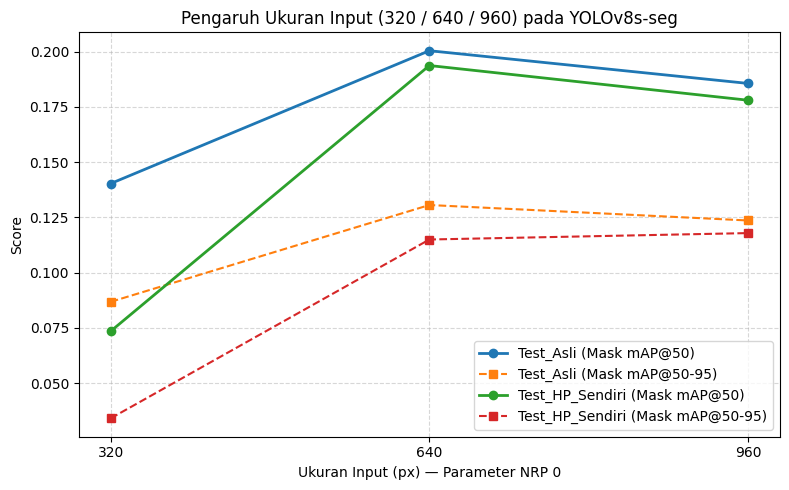

In [ ]:
df_yolo = df_all[df_all['model'] == 'YOLOv8s-seg']
plt.figure(figsize=(8, 5))
for ds_name, grp in df_yolo.groupby('dataset'):
    grp = grp.sort_values('imgsz')
    plt.plot(grp['imgsz'], grp['mask_mAP50'], marker='o', linewidth=2, label=f'{ds_name} (Mask mAP@50)')
    plt.plot(grp['imgsz'], grp['mask_mAP50_95'], marker='s', linestyle='--', label=f'{ds_name} (Mask mAP@50-95)')

plt.xticks([320, 640, 960])
plt.xlabel('Ukuran Input (px) — Parameter NRP 0')
plt.ylabel('Score')
plt.title('Pengaruh Ukuran Input (320 / 640 / 960) pada YOLOv8s-seg')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(EXPORTS_DIR, 'chart_nrp0_input_size.png'), dpi=150)
plt.show()


## 3. Eksperimen Kecil Uji Hipotesis Kegagalan (5 Foto Gagal)
Masukkan nama file **5 foto gagal** dari folder test set HP Anda di daftar `FAILED_IMAGES` di bawah ini.
Skrip akan:
1. Membandingkan prediksi **320 vs 640 vs 960** (menguji hipotesis resolusi prototype mask YOLO yang berukuran 1/4 input: 80×80 vs 160×160 vs 240×240).
2. Membandingkan **foto asli vs foto setelah CLAHE** (menguji hipotesis kegagalan akibat cahaya redup / *backlight*).


Contoh nama file di Test HP: ['indoor_001_WhatsApp-Image-2026-11-19-at-20-06-51-1-_jpeg.rf.21838ff7f5207b01d79478c77fbb5ad0.jpg', 'indoor_002_WhatsApp-Image-2026-11-24-at-15-30-51_jpeg.rf.308a5082c6cbe1c064b8fa0d2dde6a9f.jpg', 'indoor_003_WhatsApp-Image-2026-11-24-at-15-30-52-1-_jpeg.rf.2af9bff2ddf9aaaf15c4c6bc123cb10b.jpg', 'indoor_004_WhatsApp-Image-2026-11-24-at-15-30-52-2-_jpeg.rf.ffa86ba570ad36d6a2e43101bf13cf52.jpg', 'indoor_005_WhatsApp-Image-2026-11-24-at-15-30-53-1-_jpeg.rf.196f0e716dfddcc688a5c6899fe206d2.jpg', 'indoor_006_WhatsApp-Image-2026-11-24-at-15-30-53-2-_jpeg.rf.7c533c77bde53d62783e6beee9392c23.jpg', 'indoor_007_WhatsApp-Image-2026-11-24-at-15-30-53_jpeg.rf.e90b966c3508886104a1a9009d79b47f.jpg', 'indoor_008_WhatsApp-Image-2026-11-24-at-15-30-56-1-_jpeg.rf.77277ae6a4a9ff738778abcdede136b3.jpg', 'indoor_009_WhatsApp-Image-2026-11-24-at-15-30-56-3-_jpeg.rf.0a52b1c416bf64257185f20ce55c97e8.jpg', 'indoor_010_WhatsApp-Image-2026-11-24-at-15-30-56_jpeg.rf.9cebe20ed13fa69adb

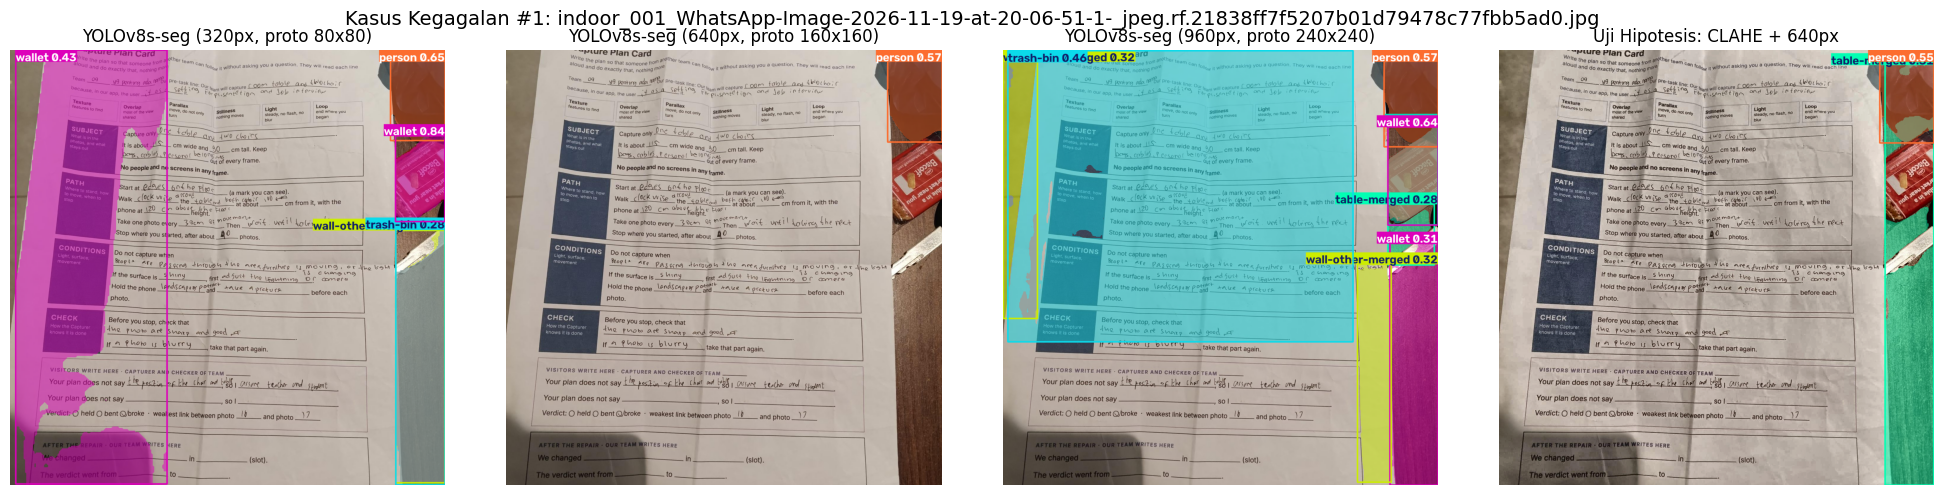

Disimpan: /content/drive/MyDrive/cpmk3-instance-segmentation/exports/failure_case_1_indoor_001_WhatsApp-Image-2026-11-19-at-20-06-51-1-_jpeg.rf.21838ff7f5207b01d79478c77fbb5ad0.png


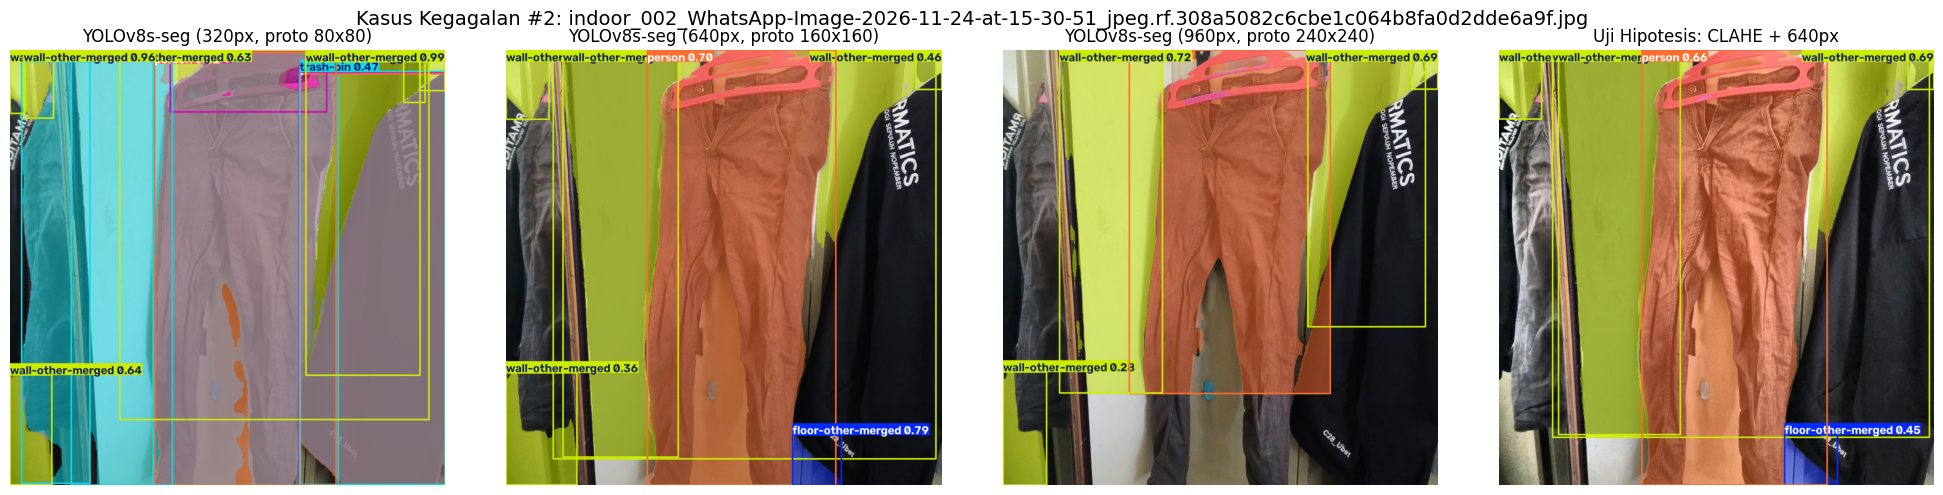

Disimpan: /content/drive/MyDrive/cpmk3-instance-segmentation/exports/failure_case_2_indoor_002_WhatsApp-Image-2026-11-24-at-15-30-51_jpeg.rf.308a5082c6cbe1c064b8fa0d2dde6a9f.png


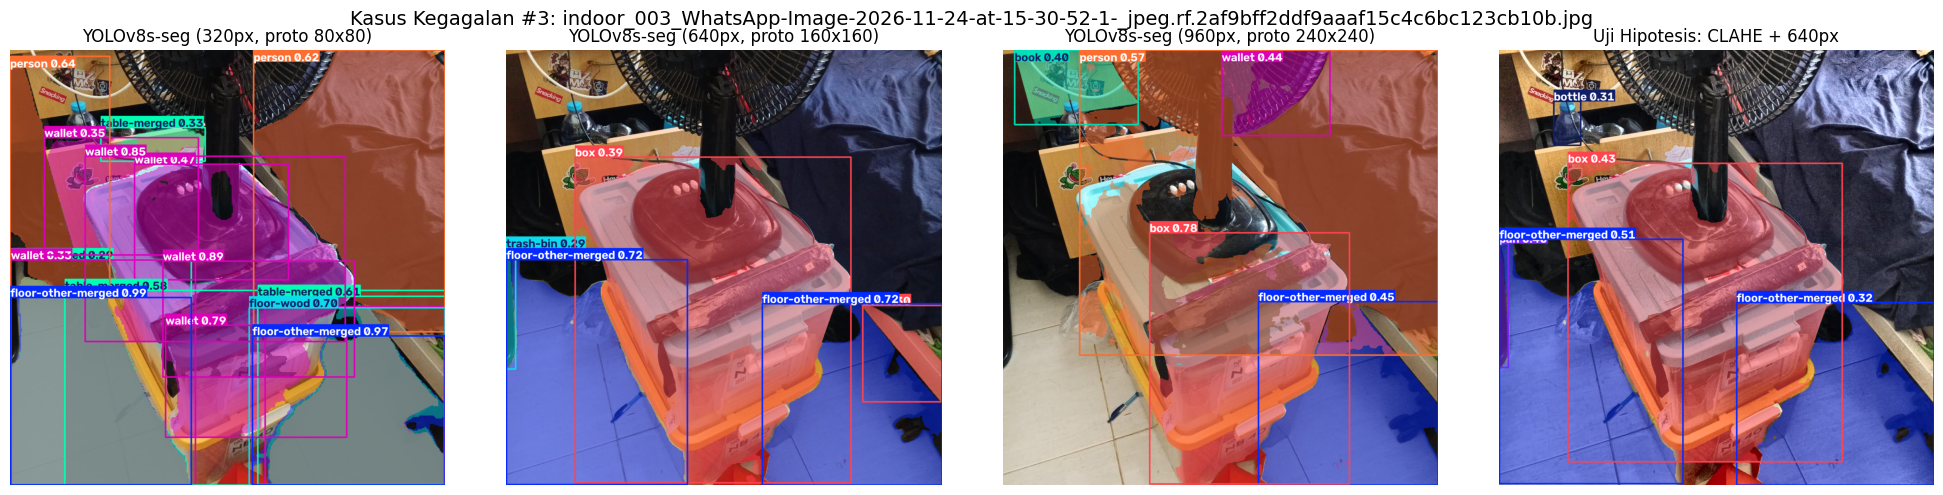

Disimpan: /content/drive/MyDrive/cpmk3-instance-segmentation/exports/failure_case_3_indoor_003_WhatsApp-Image-2026-11-24-at-15-30-52-1-_jpeg.rf.2af9bff2ddf9aaaf15c4c6bc123cb10b.png


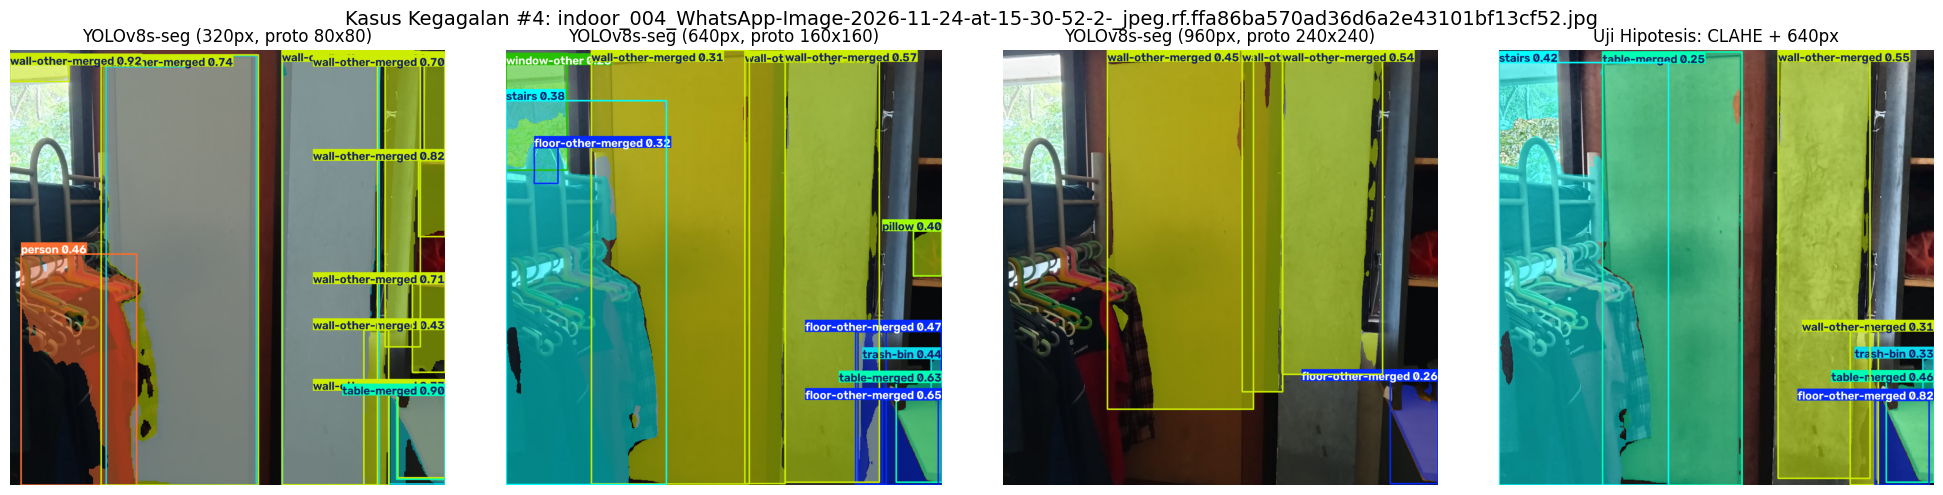

Disimpan: /content/drive/MyDrive/cpmk3-instance-segmentation/exports/failure_case_4_indoor_004_WhatsApp-Image-2026-11-24-at-15-30-52-2-_jpeg.rf.ffa86ba570ad36d6a2e43101bf13cf52.png


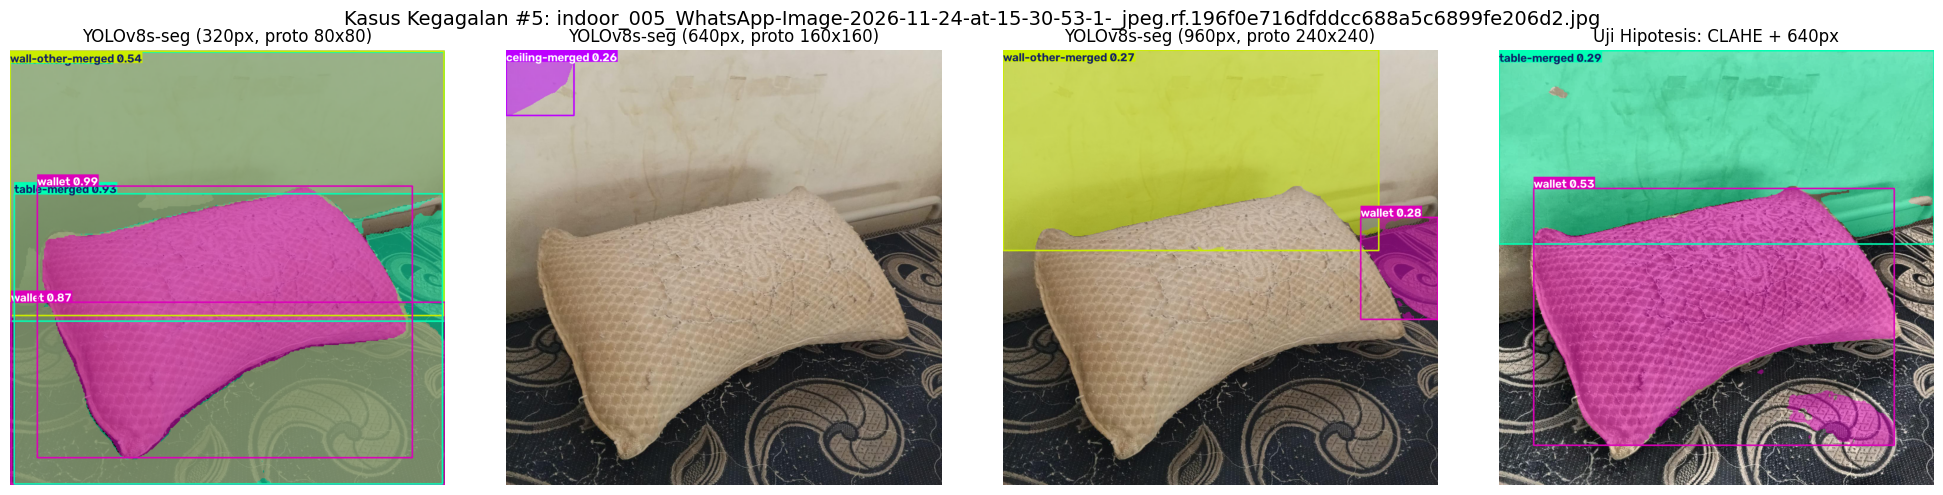

Disimpan: /content/drive/MyDrive/cpmk3-instance-segmentation/exports/failure_case_5_indoor_005_WhatsApp-Image-2026-11-24-at-15-30-53-1-_jpeg.rf.196f0e716dfddcc688a5c6899fe206d2.png


In [ ]:
HP_IMG_DIR = os.path.join(PROJECT_DIR, 'datasets', 'custom_hp_yolo', 'test', 'images')
if not os.path.exists(HP_IMG_DIR):
    HP_IMG_DIR = os.path.join(PROJECT_DIR, 'datasets', 'custom_hp_yolo', 'train', 'images')

# Tampilkan 10 file pertama agar mudah memilih 5 foto gagal
sample_files = sorted(os.listdir(HP_IMG_DIR))
print('Contoh nama file di Test HP:', sample_files[:10])

# === GANTI DENGAN 5 NAMA FILE FOTO GAGAL ANDA ===
FAILED_IMAGES = sample_files[:5]

def apply_clahe(bgr_img):
    lab = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    merged = cv2.merge((cl, a, b))
    return cv2.cvtColor(merged, cv2.COLOR_LAB2BGR)

models_yolo = {}
for sz in [320, 640, 960]:
    pt = os.path.join(PROJECT_DIR, 'runs', 'yolov8_seg', f'yolov8s_seg_img{sz}', 'weights', 'best.pt')
    if os.path.exists(pt):
        models_yolo[sz] = YOLO(pt)

for idx, fname in enumerate(FAILED_IMAGES, 1):
    fpath = os.path.join(HP_IMG_DIR, fname)
    if not os.path.exists(fpath):
        continue
    img_bgr = cv2.imread(fpath)
    img_clahe = apply_clahe(img_bgr)

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    # Panel 1-3: Uji Resolusi (320 / 640 / 960)
    for ax_i, sz in enumerate([320, 640, 960]):
        if sz in models_yolo:
            res = models_yolo[sz].predict(img_bgr, imgsz=sz, conf=0.25, verbose=False)[0]
            vis = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
            axes[ax_i].imshow(vis)
            axes[ax_i].set_title(f'YOLOv8s-seg ({sz}px, proto {sz//4}x{sz//4})')
        axes[ax_i].axis('off')

    # Panel 4: Uji CLAHE pada 640px (untuk kasus low-light / backlight)
    if 640 in models_yolo:
        res_c = models_yolo[640].predict(img_clahe, imgsz=640, conf=0.25, verbose=False)[0]
        vis_c = cv2.cvtColor(res_c.plot(), cv2.COLOR_BGR2RGB)
        axes[3].imshow(vis_c)
        axes[3].set_title('Uji Hipotesis: CLAHE + 640px')
    axes[3].axis('off')

    plt.suptitle(f'Kasus Kegagalan #{idx}: {fname}', fontsize=14)
    plt.tight_layout()
    out_fig = os.path.join(EXPORTS_DIR, f'failure_case_{idx}_{os.path.splitext(fname)[0]}.png')
    plt.savefig(out_fig, dpi=150)
    plt.show()
    print('Disimpan:', out_fig)


In [ ]:
import os, zipfile
from google.colab import files
PDIR = '/content/drive/MyDrive/cpmk3-instance-segmentation'
zip_out = '/content/colab_results_final.zip'
with zipfile.ZipFile(zip_out, 'w') as zf:
    for folder in ['logs', 'exports']:
        fdir = os.path.join(PDIR, folder)
        if os.path.exists(fdir):
            for root, _, fns in os.walk(fdir):
                for fn in fns:
                    full = os.path.join(root, fn)
                    zf.write(full, arcname=os.path.relpath(full, PDIR))
    for sz in [320, 640, 960]:
        rcsv = os.path.join(PDIR, 'runs', 'yolov8_seg', f'yolov8s_seg_img{sz}', 'results.csv')
        if os.path.exists(rcsv):
            zf.write(rcsv, arcname=f'logs/yolov8_results_{sz}.csv')
files.download(zip_out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

PDIR = '/content/drive/MyDrive/cpmk3-instance-segmentation'
for folder in ['logs', 'exports', 'runs/yolov8_seg']:
    fdir = os.path.join(PDIR, folder)
    if os.path.exists(fdir):
        files = os.listdir(fdir)
        print(f'{folder}: {files[:10]}')
    else:
        print(f'{folder}: TIDAK ADA')

logs: TIDAK ADA
exports: TIDAK ADA
runs/yolov8_seg: TIDAK ADA
